# Accounts-payable automation: invoice PDF extraction, three-way match and exception routing
**Business problem.** AP teams re-key invoice PDFs, check them against purchase orders and receipts, and try to catch duplicates and fraud. This notebook automates that pipeline end to end:

1. **Extract** header fields and line items from invoice PDFs in three different vendor layouts (`pdfplumber`).
2. **Validate:** arithmetic, vendor master, remit-to bank account, PO and goods receipt (**three-way match**), and **duplicate detection**, including re-numbered and re-formatted invoice numbers.
3. **Route** exceptions with a reason code and draft vendor query emails (saved as `.eml` drafts, never sent).
4. **Report** AP aging and the cash needed by week.

> All vendors, POs and invoices are **synthetic** (`make_invoices.py`), so the work can be shared. Known problems are planted so detection can be measured: math errors, price variances, quantity over receipt, missing PO, changed bank details and three kinds of duplicate.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import re, difflib, json, email.message
from datetime import date, timedelta
import pdfplumber
import make_invoices
n = make_invoices.build()            # rebuild the synthetic dataset (deterministic)
vm = pd.read_csv("data/vendor_master.csv"); po = pd.read_csv("data/purchase_orders.csv"); gr = pd.read_csv("data/goods_receipts.csv")
truth = pd.read_csv("data/ground_truth.csv").fillna({"planted_issue": ""})
print(n, "invoice PDFs;", len(vm), "vendors;", len(po), "purchase orders")
vm

75 invoice PDFs; 12 vendors; 72 purchase orders


,vendor_id,name,terms,bank,layout
0,V001,Northwind Office Supply LLC,Net 30,****4421,0
1,V002,Bluepeak IT Services Inc,Net 45,****9087,1
2,V003,Harbor Janitorial Co,Net 15,****1132,2
3,V004,Summit Print & Mail,Net 30,****7765,0
4,V005,Keystone Facilities Group,Net 30,****3310,1
5,V006,Redline Courier Services,Net 15,****5528,2
6,V007,Greenfield Catering LLC,Net 30,****2049,0
7,V008,Atlas Software Licensing,Net 60,****6671,1
8,V009,Pioneer Electrical Contractors,Net 30,****8893,2
9,V010,Clearwater Bottled Water,Net 15,****4410,0


In [2]:
with pdfplumber.open("data/invoices/inv_002.pdf") as pdf:
    print(pdf.pages[0].extract_text(layout=True)[:900])

                                                                                    
                                                                                    
                                                                                    
                       KEYSTONE      FACILITIES     GROUP                           
                                    Statement of charges                            
                                                                                    
                                                                                    
        Bill #: 05-7490                       Purchase Order: PO-26001              
        Date: 2026-09-02                      Payment terms: Net 30                 
                                                                                    
                                                  


## Extraction
One parser handles all three layouts:
* **Labels vary** (`Invoice No` / `Bill #` / `Ref`, `Total Due` / `AMOUNT DUE` / `TOTAL`), so each field has a list of synonyms.
* **The vendor** is the closest fuzzy match between the first lines of the page and the vendor master.
* **Line items** are read using the column order in the header row (`Description, Qty, Unit Price, Amount` vs `Amount, Item, Quantity, Rate`), or the `qty x price = amount` pattern for the compact layout. Numbers inside descriptions ("Binders, box of 12") are handled by reading the numeric columns from the ends of the line.

In [3]:
NUM = r"[\d,]+\.\d{2}"
FIELDS = {"invoice_no": [r"Invoice No:\s*(\S+)", r"Bill #:\s*(\S+)", r"Ref\.+:\s*(\S+)"],
          "invoice_date": [r"Invoice Date:\s*(\d{4}-\d{2}-\d{2})", r"Date:\s*(\d{4}-\d{2}-\d{2})", r"Issued\.+:\s*(\d{4}-\d{2}-\d{2})"],
          "po": [r"PO Number:\s*(\S+)", r"Purchase Order:\s*(\S+)", r"Your PO\.+:\s*(\S+)"],
          "terms": [r"Terms:\s*(Net \d+)", r"Payment terms:\s*(Net \d+)", r"Terms\.+:\s*(Net \d+)"],
          "subtotal": [rf"Subtotal\s*\$?({NUM})", rf"Net amount:\s*({NUM})", rf"Sub-total\s+({NUM})"],
          "tax": [rf"Sales Tax \(6%\)\s*\$?({NUM})", rf"Tax:\s*({NUM})", rf"Tax 6\.00%\s+({NUM})"],
          "total": [rf"Total Due\s*\$?({NUM})", rf"AMOUNT DUE USD\s*({NUM})", rf"TOTAL\s+({NUM})"],
          "bank": [r"account (\*{4}\d{4})", r"ACH to (\*{4}\d{4})", r"Bank: (\*{4}\d{4})"]}
money = lambda s: float(s.replace(",", ""))

def parse_lines(lines):
    items, order = [], None
    for ln in lines:
        low = ln.lower()
        if ("description" in low or "item" in low) and ("qty" in low or "quantity" in low):
            pos = {k: low.find(w) for k, w in [("desc", "description" if "description" in low else "item"),
                   ("qty", "qty" if "qty" in low else "quantity"), ("unit", "unit price" if "unit price" in low else "rate"), ("amt", "amount")]}
            order = sorted(pos, key=pos.get); continue
        m = re.match(rf"^(.+?)\s+([\d.]+)\s+x\s+({NUM})\s+=\s+({NUM})$", ln.strip())
        if m:
            items.append([m[1].strip(), float(m[2]), money(m[3]), money(m[4])]); continue
        if order:
            toks = ln.split(); isnum = lambda t: re.fullmatch(r"[\d,]+(?:\.\d+)?", t) is not None
            k = order.index("desc"); pre, post = order[:k], order[k + 1:]
            if len(toks) < len(order) or not all(isnum(t) for t in toks[:len(pre)] + toks[len(toks) - len(post):]):
                continue
            desc = " ".join(toks[len(pre):len(toks) - len(post)])
            if not desc or re.search(r"total|tax|amount|net|due", desc, re.I):
                continue
            rec = dict(zip(pre, map(money, toks[:len(pre)]))) | dict(zip(post, map(money, toks[len(toks) - len(post):])))
            items.append([desc, rec["qty"], rec["unit"], rec["amt"]])
    return items

def extract(path):
    with pdfplumber.open(path) as pdf:
        text = pdf.pages[0].extract_text()
    lines = text.splitlines()
    out = {"file": path.name}
    for f, pats in FIELDS.items():
        val = next((m[1] for p in pats if (m := re.search(p, text))), None)
        out[f] = money(val) if f in ("subtotal", "tax", "total") and val else val
    if out["po"] in ("N/A", "none", "-"): out["po"] = None
    heads = [l.split("|")[0].strip().lower() for l in lines[:3] if l.strip().upper() != "INVOICE"]
    scores = {r.vendor_id: max(difflib.SequenceMatcher(None, h, r.name.lower()).ratio() for h in heads) for r in vm.itertuples()}
    out["vendor_id"], out["vendor_match"] = max(scores.items(), key=lambda kv: kv[1])
    out["lines"] = parse_lines(lines)
    return out

ext = [extract(p) for p in sorted(pathlib.Path("data/invoices").glob("*.pdf"))]
X = pd.DataFrame(ext)
X.drop(columns="lines").head()

,file,invoice_no,invoice_date,po,terms,subtotal,tax,total,bank,vendor_id,vendor_match
0,inv_001.pdf,08-4050,2026-10-27,PO-26000,Net 60,3264.00,195.84,3459.84,****6671,V008,1.0
1,inv_002.pdf,05-7490,2026-09-02,PO-26001,Net 30,1040.00,62.40,1102.40,****3310,V005,1.0
2,inv_003.pdf,11-1975,2026-09-05,PO-26002,Net 30,4200.00,252.00,4452.00,****0937,V011,1.0
3,inv_004.pdf,04-5819,2026-09-26,PO-26003,Net 30,2121.74,127.30,2249.04,****7765,V004,1.0
4,inv_005.pdf,11-2363,2026-10-19,PO-26004,Net 30,26.00,1.56,27.56,****0937,V011,1.0


In [4]:
# field-level extraction accuracy against the generator's ground truth
T = truth.set_index("file"); E = X.set_index("file")
acc = {}
for f in ["vendor_id", "invoice_no", "invoice_date", "po", "subtotal", "tax", "total", "bank"]:
    a, b = E[f], T.loc[E.index, f]
    same = [(pd.isna(x) and pd.isna(y)) or (x == y) or (isinstance(x, float) and isinstance(y, float) and abs(x - y) < 0.005) for x, y in zip(a, b)]
    acc[f] = np.mean(same)
n_lines = sum(len(l) for l in X["lines"])
print(f"line items extracted: {n_lines}")
pd.Series(acc, name="field accuracy").to_frame().T

line items extracted: 110


,vendor_id,invoice_no,invoice_date,po,subtotal,tax,total,bank
field accuracy,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## Validation rules
| Code | Rule |
|---|---|
| `MATH` | a line's qty × price ≠ amount, or lines don't sum to the subtotal, or subtotal + tax ≠ total |
| `TAX` | tax ≠ 6% of subtotal (±1 cent) |
| `VENDOR` | vendor not found in the master (fuzzy match below 0.85) |
| `BANK` | remit-to account differs from the vendor master: **possible payment fraud**, call the vendor on a known number |
| `NO_PO` | no purchase order quoted |
| `PO_VENDOR` | PO belongs to a different vendor |
| `PRICE` | unit price more than 2% above the PO price |
| `QTY` | invoiced quantity exceeds goods received |
| `DUP` | same vendor and same invoice number after normalisation (case, spaces, punctuation) |
| `DUP?` | same vendor, same total and same PO, dated within 30 days (possible re-numbered resubmission) |

In [5]:
po_idx = po.set_index("po"); gr_idx = gr.set_index("po"); vmi = vm.set_index("vendor_id")
X["norm_no"] = X["invoice_no"].str.upper().str.replace(r"[^A-Z0-9]", "", regex=True)
X["date"] = pd.to_datetime(X["invoice_date"])
X = X.sort_values(["date", "file"]).reset_index(drop=True)
flags = {i: [] for i in X.index}
seen = []
for i, r in X.iterrows():
    f = flags[i]
    L = r["lines"]
    if any(abs(q * u - a) > 0.01 for _, q, u, a in L) or abs(sum(l[3] for l in L) - r.subtotal) > 0.01 or abs(r.subtotal + r.tax - r.total) > 0.01:
        f.append("MATH")
    if abs(round(r.subtotal * 0.06, 2) - r.tax) > 0.011: f.append("TAX")
    if r.vendor_match < 0.85: f.append("VENDOR")
    elif r.bank != vmi.loc[r.vendor_id, "bank"]: f.append("BANK")
    if pd.isna(r.po) or not r.po: f.append("NO_PO")
    elif r.po in po_idx.index:
        p = po_idx.loc[r.po]
        if p.vendor_id != r.vendor_id: f.append("PO_VENDOR")
        po_price = {d: u for d, q, u in json.loads(p.lines)}
        if any(u > po_price.get(d, np.inf) * 1.02 for d, q, u, a in L): f.append("PRICE")
        if sum(q for _, q, _, _ in L) > gr_idx.loc[r.po, "received_qty"]: f.append("QTY")
    for j in seen:
        s = X.loc[j]
        if s.vendor_id == r.vendor_id and s.norm_no == r.norm_no: f.append("DUP"); break
        if s.vendor_id == r.vendor_id and abs(s.total - r.total) < 0.01 and abs((r.date - s.date).days) <= 30 and s.po == r.po:
            f.append("DUP?"); break
    seen.append(i)
X["flags"] = [",".join(flags[i]) for i in X.index]
X["status"] = np.where(X["flags"] == "", "auto-approve", "exception")
X["status"].value_counts()

status
auto-approve    55
exception       20
Name: count, dtype: int64

In [6]:
# detection performance against the planted problems
expected = {"math_error": "MATH", "price_variance": "PRICE", "bank_change": "BANK", "no_po": "NO_PO", "qty_over_receipt": "QTY",
            "duplicate_exact": "DUP", "duplicate_reformatted": "DUP", "duplicate_new_number": "DUP?"}
m = X.merge(truth[["file", "planted_issue"]], on="file")
m["caught"] = [int(expected.get(p, "") in fl.split(",")) if p else 0 for p, fl in zip(m.planted_issue, m["flags"])]
det = m[m.planted_issue != ""].groupby("planted_issue")["caught"].agg(["size", "sum"]).rename(columns={"size": "planted", "sum": "caught"})
clean = m[m.planted_issue == ""]
print(f"clean invoices wrongly flagged: {(clean['flags'] != '').sum()} of {len(clean)}")
# why the DUP? rule also requires the same PO: without it, recurring fixed-price services look like duplicates
loose = sum(1 for i, r in X.iterrows() for j in X.index[:i]
            if X.at[j, "vendor_id"] == r.vendor_id and abs(X.at[j, "total"] - r.total) < 0.01 and abs((r.date - X.at[j, "date"]).days) <= 30
            and X.at[j, "norm_no"] != r.norm_no and truth.set_index("file").loc[r.file, "planted_issue"] == "")
print(f"clean invoices a looser same-vendor/same-amount rule would have flagged: {loose}")
det

clean invoices wrongly flagged: 0 of 55


clean invoices a looser same-vendor/same-amount rule would have flagged: 3


,planted,caught
planted_issue,,
bank_change,4,4
duplicate_exact,1,1
duplicate_new_number,1,1
duplicate_reformatted,1,1
math_error,7,7
no_po,2,2
price_variance,3,3
qty_over_receipt,1,1


In [7]:
exc = X[X.status == "exception"][["file", "vendor_id", "invoice_no", "invoice_date", "po", "total", "flags"]]
exc.assign(vendor=exc.vendor_id.map(vmi["name"])).sort_values("flags")

,file,vendor_id,invoice_no,invoice_date,po,total,flags,vendor
3,inv_054.pdf,V008,08-5263,2026-08-31,PO-26053,3561.60,BANK,Atlas Software Licensing
70,inv_064.pdf,V001,01-8885,2026-11-08,PO-26063,591.48,BANK,Northwind Office Supply LLC
52,inv_009.pdf,V005,05-2933,2026-10-19,PO-26008,589.36,BANK,Keystone Facilities Group
16,inv_060.pdf,V004,04-4921,2026-09-14,PO-26059,678.40,BANK,Summit Print & Mail
18,inv_073.pdf,V006,06-2768,2026-09-17,PO-26005,25.97,DUP,Redline Courier Services
19,inv_075.pdf,V009,097725,2026-09-17,PO-26040,461.10,DUP,Pioneer Electrical Contractors
47,inv_074.pdf,V002,02-7417,2026-10-10,PO-26017,402.80,DUP?,Bluepeak IT Services Inc
64,inv_029.pdf,V007,07-9430,2026-11-02,PO-26028,2162.40,MATH,Greenfield Catering LLC
57,inv_037.pdf,V005,05-4111,2026-10-25,PO-26036,551.20,MATH,Keystone Facilities Group
27,inv_014.pdf,V007,07-4981,2026-09-23,PO-26013,360.40,MATH,Greenfield Catering LLC


## Vendor query drafts
Each exception gets a short, specific email to the vendor (or, for `BANK`, an internal alert, because changed bank details must be verified by phone on a number from the master file, never by replying to the invoice). Drafts are written to `outbox/` as `.eml` files for a person to review and send.

In [8]:
REASON = {"MATH": "the line amounts and totals on the invoice do not add up", "TAX": "the sales tax does not equal 6% of the subtotal",
          "NO_PO": "no purchase order number is quoted", "PRICE": "a unit price is higher than the agreed purchase-order price",
          "QTY": "the invoiced quantity is more than we have received", "PO_VENDOR": "the purchase order quoted belongs to another supplier",
          "DUP": "it appears to duplicate an invoice we have already received", "DUP?": "it matches the amount of a recent invoice and may be a resubmission"}
out = pathlib.Path("outbox"); out.mkdir(exist_ok=True)
for f in out.glob("*.eml"): f.unlink()
for r in X[X.status == "exception"].itertuples():
    codes = r.flags.split(","); msg = email.message.EmailMessage()
    if "BANK" in codes:
        msg["To"] = "ap-controls@example.org"; msg["Subject"] = f"ALERT: bank details changed on {vmi.loc[r.vendor_id, 'name']} invoice {r.invoice_no}"
        msg.set_content(f"Invoice {r.invoice_no} (${r.total:,.2f}) asks for payment to {r.bank}, but the vendor master holds "
                        f"{vmi.loc[r.vendor_id, 'bank']}. Hold payment and verify by phone using the number on file.")
    else:
        msg["To"] = f"billing@{r.vendor_id.lower()}.example.com"; msg["Subject"] = f"Query on invoice {r.invoice_no}"
        reasons = "; ".join(REASON[c] for c in codes if c in REASON)
        msg.set_content(f"Hello {vmi.loc[r.vendor_id, 'name']} team,\n\nWe are holding invoice {r.invoice_no} dated {r.invoice_date} "
                        f"for ${r.total:,.2f} because {reasons}. Please send a corrected invoice or confirm the details.\n\nThank you,\nAccounts Payable")
    msg["From"] = "accounts.payable@example.org"
    (out / f"{r.file[:-4]}.eml").write_bytes(bytes(msg))
print(len(list(out.glob("*.eml"))), "drafts written; example:\n")
print(next(out.glob("*.eml")).read_text())

20 drafts written; example:

To: billing@v007.example.com
Subject: Query on invoice 07-9430
Content-Type: text/plain; charset="utf-8"
Content-Transfer-Encoding: quoted-printable
MIME-Version: 1.0
From: accounts.payable@example.org

Hello Greenfield Catering LLC team,

We are holding invoice 07-9430 dated 2026-11-02 for $2,162.40 because the lin=
e amounts and totals on the invoice do not add up. Please send a corrected in=
voice or confirm the details.

Thank you,
Accounts Payable



## AP aging and cash requirement
Every invoice received since late August is treated as still open on 12 November 2026. Approved invoices are scheduled for payment on their due date (invoice date + terms). Anything already past due goes into the next payment run; exceptions stay on hold until they are resolved.

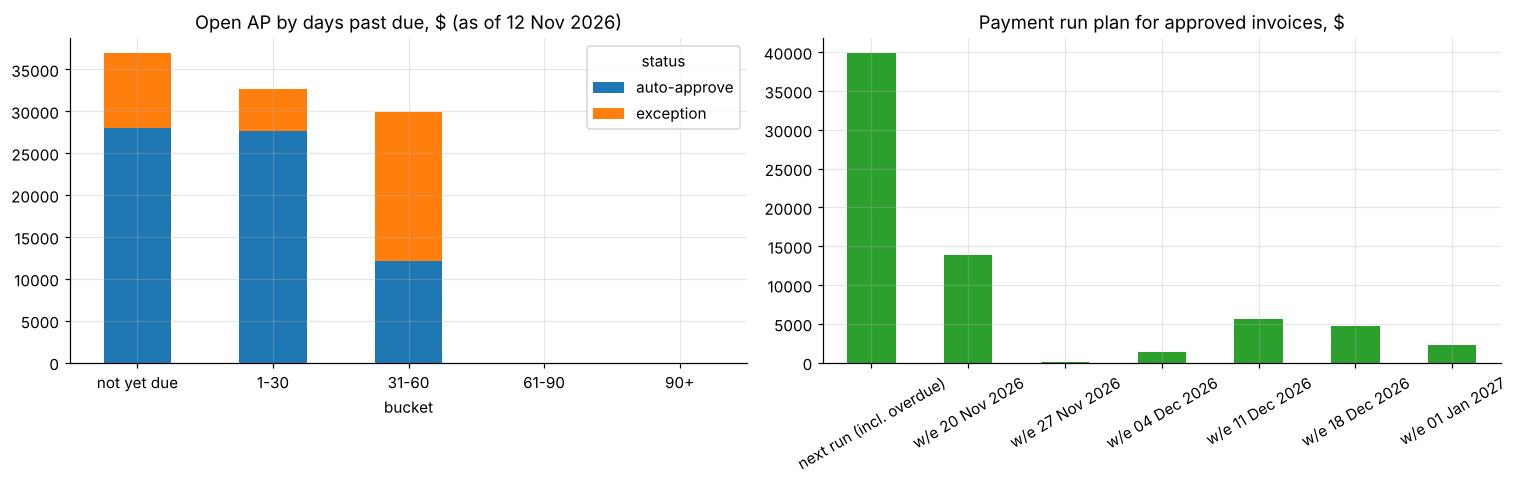

status,auto-approve,exception
bucket,,
not yet due,27991.0,8921.0
1-30,27647.0,5062.0
31-60,12090.0,17885.0
61-90,0.0,0.0
90+,0.0,0.0
Total,67728.0,31867.0


In [9]:
asof = pd.Timestamp("2026-11-12")
X["due"] = X["date"] + pd.to_timedelta(X["terms"].str.extract(r"(\d+)")[0].astype(int), unit="D")
X["days_past_due"] = (asof - X["due"]).dt.days
X["bucket"] = pd.cut(X["days_past_due"], [-999, 0, 30, 60, 90, 999], labels=["not yet due", "1-30", "31-60", "61-90", "90+"])
aging = X.pivot_table(index="bucket", columns="status", values="total", aggfunc="sum", fill_value=0, observed=False)
aging.loc["Total"] = aging.sum()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
aging.drop("Total").plot.bar(ax=axes[0], stacked=True, title="Open AP by days past due, $ (as of 12 Nov 2026)", rot=0)
appr = X[X.status == "auto-approve"].copy()
appr["week_end"] = appr.due.where(appr.due >= asof, asof).dt.to_period("W-FRI").dt.end_time.dt.normalize()
plan = appr.groupby("week_end")["total"].sum()
plan.index = ["next run (incl. overdue)" if i == 0 else f"w/e {d:%d %b %Y}" for i, d in enumerate(plan.index)]
plan.plot.bar(ax=axes[1], color="C2", rot=30, title="Payment run plan for approved invoices, $")
axes[1].set_xlabel("")
plt.tight_layout(); plt.savefig(IMG / "aging_cash.png", bbox_inches="tight"); plt.show()
aging.round(0)

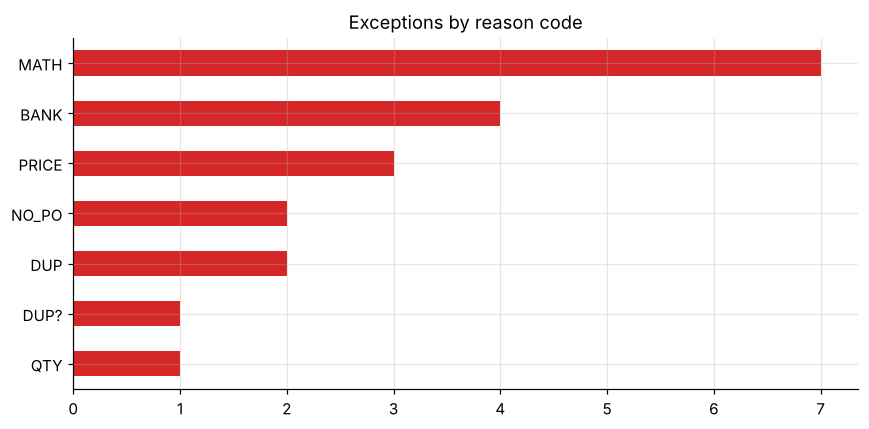

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
codes = pd.Series([c for f in X["flags"] if f for c in f.split(",")]).value_counts()
codes.plot.barh(ax=ax, color="C3", title="Exceptions by reason code"); ax.invert_yaxis()
plt.tight_layout(); plt.savefig(IMG / "exceptions.png", bbox_inches="tight"); plt.show()

## Findings
* **Extraction:** 75 invoices in three layouts, 110 line items, and 100% accuracy on all eight header fields (vendor, invoice number, date, PO, subtotal, tax, total and remit-to account) against the generator's ground truth.
* **Controls:** all 20 planted problems were caught, with no false positives on the 55 clean invoices. The problems were 7 arithmetic errors, 4 changed bank accounts, 3 price variances, 2 missing POs, 1 quantity over receipt and 3 duplicates (an exact repeat, one with the hyphen removed from the number, and one re-numbered).
* **Rule design matters.** A looser "same vendor, same amount within 30 days" duplicate rule would also have flagged 3 legitimate recurring fixed-price services (HVAC visits, water delivery, cleaning). Requiring the same PO removes those false alarms and still catches the re-numbered resubmission.
* **Throughput:** 55 of 75 invoices (73%) pass straight through ($67.7k). The 20 exceptions ($31.9k) go to a reviewer with a reason code and a ready-to-send draft. Changed bank details go to an internal controls mailbox, not the vendor, as a fraud safeguard.
* **Limitations:** the PDFs are machine-generated text. Scanned invoices would need OCR (e.g. Tesseract) in front of the same parser, and a production system would learn new layouts or use a document-AI model rather than hand-written label synonyms.